# NASA Exoplanet Archive: discovery trends and catalogue quality

**Research question:** How do discovery methods and reported planet properties vary across the confirmed-planet catalogue, and which data-quality limitations affect interpretation?

Data source: NASA Exoplanet Archive, **Planetary Systems Composite Parameters (`pscomppars`)** via TAP. Data are refreshed on each execution and thus results change over time.

This notebook completes the exploratory analysis begun in `NASA_Exoplanet_Discovery_Analytics.ipynb`; the earlier notebook is preserved unchanged. Findings are *descriptive*, not causal. The catalogue has selection effects, heterogenous measurement uncertainties and missing values.

**Reproduction:** install `requirements.txt`, connect to the internet, and Run All.

In [1]:
from datetime import datetime, timezone
from io import StringIO
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TAP_URL = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"
COLUMNS = [
  "pl_name", "hostname", "discoverymethod", "disc_year", "disc_facility",
  "sy_dist", "pl_orbper", "pl_orbsmax", "pl_rade", "pl_bmasse", "pl_eqt",
  "pl_orbeccen", "st_teff", "st_rad", "st_mass", "st_met"
]
query = f"SELECT {','.join(COLUMNS)} FROM pscomppars"
retrieved_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
r = requests.get(TAP_URL, params={"query": query, "format": "csv"}, timeout=120)
r.raise_for_status()
df = pd.read_csv(StringIO(r.text))
print("Retrieved UTC:", retrieved_at)
print("Source:", TAP_URL)
print("Catalogue rows:", len(df), "| columns:", len(df.columns))
display(df.head())

Retrieved UTC: 2026-10-21T02:25:48+00:00
Source: https://exoplanetarchive.ipac.caltech.edu/TAP/sync
Catalogue rows: 6451 | columns: 16


,pl_name,hostname,discoverymethod,disc_year,disc_facility,sy_dist,pl_orbper,pl_orbsmax,pl_rade,pl_bmasse,pl_eqt,pl_orbeccen,st_teff,st_rad,st_mass,st_met
0,55 Cnc b,55 Cnc,Radial Velocity,1996,Lick Observatory,12.5855,14.651552,0.11800,13.900,263.9785,700.00,0.0029,5198.0,0.980,1.015,0.39
1,55 Cnc c,55 Cnc,Radial Velocity,2004,McDonald Observatory,12.5855,44.393600,0.24700,8.510,54.4738,499.27,0.0880,5198.0,0.980,1.015,0.39
2,55 Cnc d,55 Cnc,Radial Velocity,2002,Lick Observatory,12.5855,4799.000000,5.60000,13.000,1232.4930,104.85,0.0913,5198.0,0.980,1.015,0.39
3,55 Cnc e,55 Cnc,Radial Velocity,2004,McDonald Observatory,12.5855,0.736547,0.01544,1.875,7.9900,1958.00,0.0500,5172.0,0.943,0.905,0.35
4,55 Cnc f,55 Cnc,Radial Velocity,2007,Multiple Observatories,12.5855,260.580000,0.80200,7.590,44.8120,277.07,0.0630,5198.0,0.980,1.015,0.39


## 1. Verify the retrieval and quantify missing data
Each row corresponds to a named planet in the composite catalogue. The checks below highlight duplicates and data completeness; we avoid silently imputing missing astrophysical measurements.

Repeated names: 0


,missing_pct
pl_orbeccen,16.56
st_met,10.84
pl_eqt,8.37
pl_orbsmax,7.67
pl_orbper,5.49
st_rad,5.15
st_teff,4.76
pl_rade,0.78
pl_bmasse,0.47
sy_dist,0.43


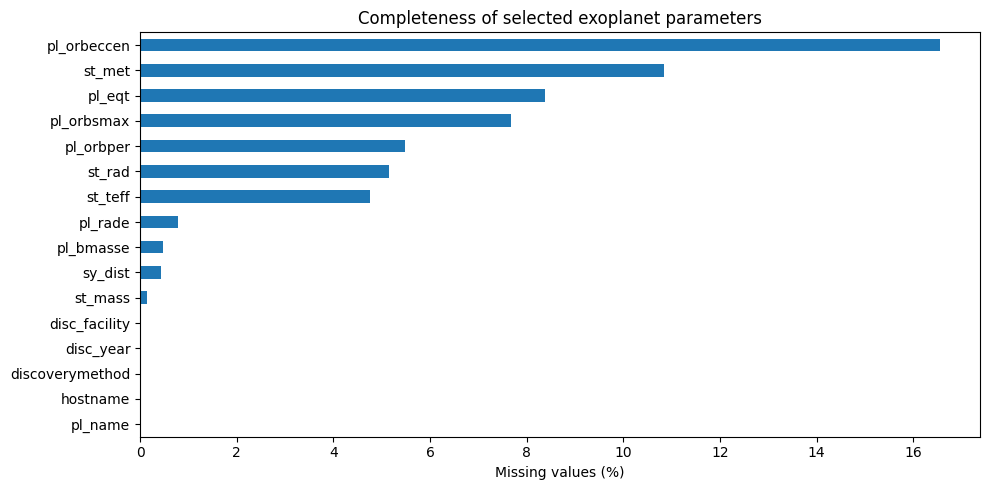

In [2]:
assert {"pl_name", "disc_year", "discoverymethod"}.issubset(df.columns)
assert len(df) > 0
print("Repeated names:", int(df.duplicated("pl_name").sum()))
missing = (100 * df.isna().mean()).sort_values(ascending=False)
display(missing.rename("missing_pct").round(2).to_frame())
fig, ax = plt.subplots(figsize=(10, 5))
missing.sort_values().plot.barh(ax=ax)
ax.set_xlabel("Missing values (%)")
ax.set_title("Completeness of selected exoplanet parameters")
plt.tight_layout()
plt.show()

## 2. Discovery chronology
These bars count catalogue records by *discovery year*, not all observational detections made in that year. Recent years may be incomplete; historical counts also reflect confirmation and archive-update timing.

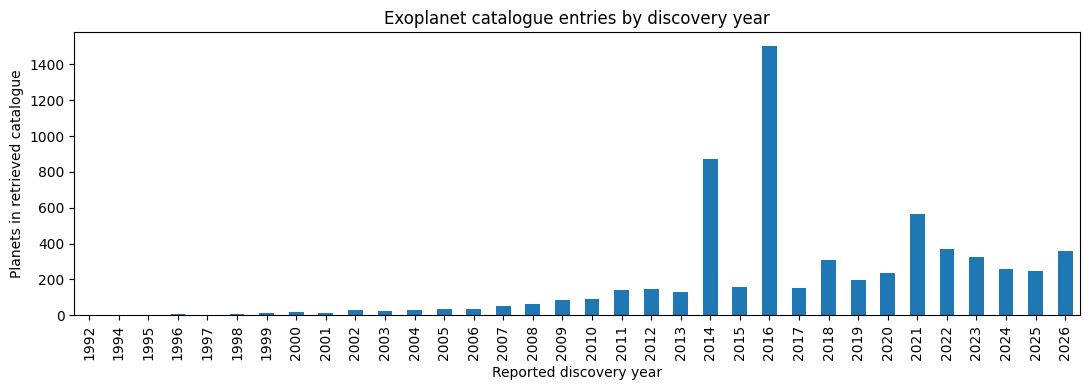

,planets
disc_year,
2015,155
2016,1504
2017,152
2018,308
2019,194
2020,234
2021,564
2022,367
2023,323


In [3]:
years = pd.to_numeric(df["disc_year"], errors="coerce").dropna().astype(int)
year_counts = years.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(11, 4))
year_counts.plot.bar(ax=ax)
ax.set_xlabel("Reported discovery year")
ax.set_ylabel("Planets in retrieved catalogue")
ax.set_title("Exoplanet catalogue entries by discovery year")
plt.tight_layout()
plt.show()
display(year_counts.tail(12).rename("planets").to_frame())

## 3. Discovery method distribution
The apparent dominance of any method reflects survey history, sensitivity, target selection and validation practices—not an intrinsic abundance of certain kinds of planets.

,planets
discoverymethod,
Transit,4785
Radial Velocity,1204
Microlensing,292
Imaging,98
Transit Timing Variations,29
Eclipse Timing Variations,17
Orbital Brightness Modulation,9
Pulsar Timing,8
Astrometry,6


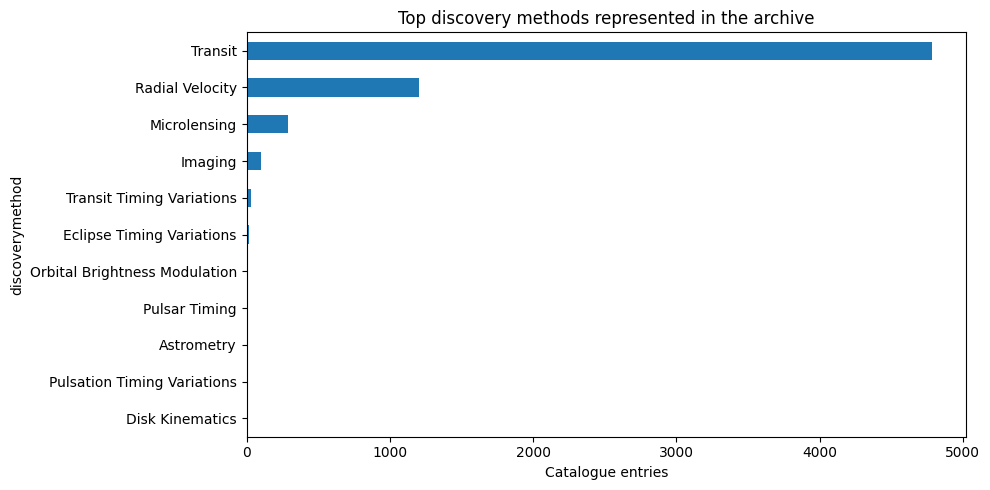

In [4]:
method_counts = df["discoverymethod"].fillna("Unspecified").value_counts()
display(method_counts.rename("planets").to_frame())
fig, ax = plt.subplots(figsize=(10, 5))
method_counts.head(12).sort_values().plot.barh(ax=ax)
ax.set_title("Top discovery methods represented in the archive")
ax.set_xlabel("Catalogue entries")
plt.tight_layout()
plt.show()

## 4. Discovery-method evolution across years
Group sparse categories into 'Other', and plot the four most represented discovery methods. Stacking shows **counts**, not the probability that a method detects a planet.

method_group,Imaging,Microlensing,Other,Radial Velocity,Transit
disc_year,,,,,
2017,3,10,4,48,87
2018,3,21,2,38,244
2019,4,14,4,65,107
2020,3,20,1,46,164
2021,5,21,4,77,457
2022,4,51,5,115,192
2023,7,30,5,56,225
2024,11,28,5,29,187
2025,8,23,9,62,144


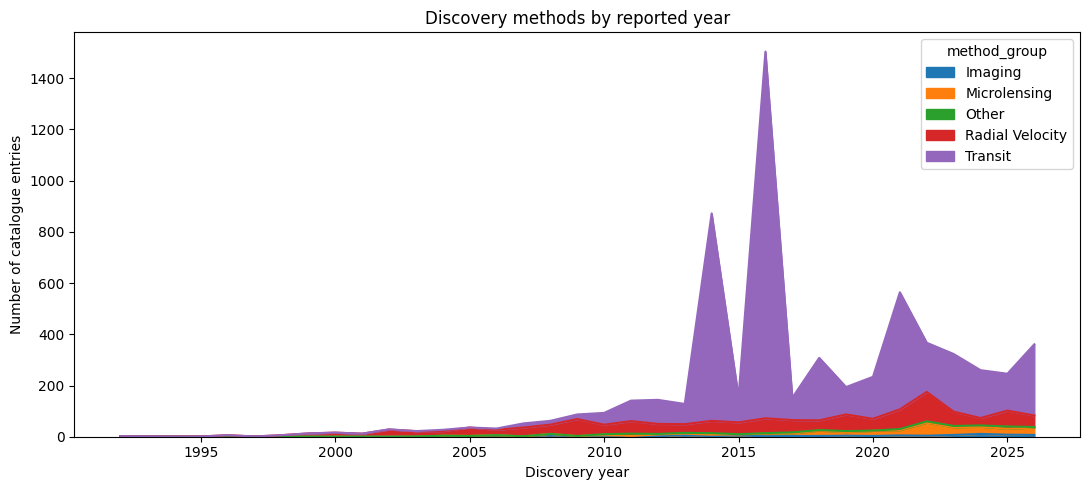

In [5]:
top_methods = method_counts.head(4).index.tolist()
trend = df[["disc_year", "discoverymethod"]].copy()
trend["disc_year"] = pd.to_numeric(trend["disc_year"], errors="coerce")
trend = trend.dropna(subset=["disc_year"])
trend["disc_year"] = trend["disc_year"].astype(int)
trend["method_group"] = trend["discoverymethod"].where(trend["discoverymethod"].isin(top_methods), "Other")
pivot = trend.groupby(["disc_year", "method_group"]).size().unstack(fill_value=0)
display(pivot.tail(10))
fig, ax = plt.subplots(figsize=(11, 5))
pivot.plot.area(ax=ax)
ax.set_ylabel("Number of catalogue entries")
ax.set_xlabel("Discovery year")
ax.set_title("Discovery methods by reported year")
plt.tight_layout()
plt.show()

## 5. Selected reported planet properties
Plot radius versus orbital period for catalogue entries that report both quantities. A log period axis accommodates the broad range. This is not a mass–radius fit or an inference about underlying occurrence rates.

Usable period-radius records: 6050 out of 6451


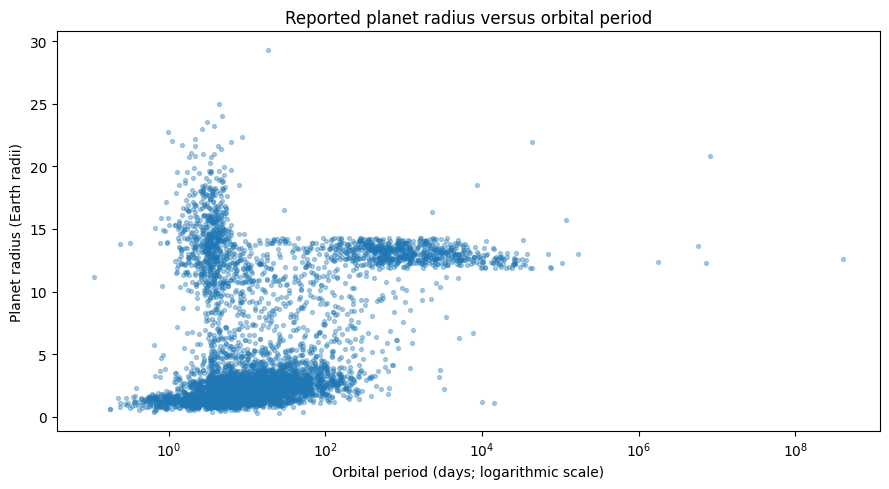

In [6]:
properties = df[["pl_orbper", "pl_rade", "discoverymethod"]].copy()
properties["pl_orbper"] = pd.to_numeric(properties["pl_orbper"], errors="coerce")
properties["pl_rade"] = pd.to_numeric(properties["pl_rade"], errors="coerce")
properties = properties.replace([np.inf, -np.inf], np.nan).dropna(subset=["pl_orbper","pl_rade"])
properties = properties.loc[(properties["pl_orbper"] > 0) & (properties["pl_rade"] > 0)]
print("Usable period-radius records:", len(properties), "out of", len(df))
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(properties["pl_orbper"], properties["pl_rade"], s=8, alpha=0.35)
ax.set_xscale("log")
ax.set_xlabel("Orbital period (days; logarithmic scale)")
ax.set_ylabel("Planet radius (Earth radii)")
ax.set_title("Reported planet radius versus orbital period")
plt.tight_layout()
plt.show()

## 6. Descriptive summary computed from the current snapshot
The narrative below is generated from the retrieved data, so it never falsely presents historical notebook outputs as current survey totals.

In [7]:
from IPython.display import Markdown, display
leading = method_counts.index[0]
leading_count = int(method_counts.iloc[0])
coverage = len(properties) / len(df) * 100
earliest = int(year_counts.index.min())
latest = int(year_counts.index.max())
display(Markdown(
  f"""### Results at {retrieved_at}
- Retrieved **{len(df):,}** composite catalogue records, spanning reported discovery years **{earliest}–{latest}**.
- The most represented discovery method in this snapshot is **{leading}** (**{leading_count:,}** records).
- **{len(properties):,}** entries (**{coverage:.1f}%**) have a positive recorded orbital period and radius for the scatter plot.
- The three least-complete selected fields are: **{', '.join(missing.head(3).index)}**.

**Interpretation:** These are descriptive patterns of the **confirmed and catalogued** population, subject to telescope selection functions, discovery-method biases, missing data and changes in archive content. They should not be read as unbiased planet-population statistics."""
))

### Results at 2026-10-21T02:25:48+00:00
- Retrieved **6,451** composite catalogue records, spanning reported discovery years **1992–2026**.
- The most represented discovery method in this snapshot is **Transit** (**4,785** records).
- **6,050** entries (**93.8%**) have a positive recorded orbital period and radius for the scatter plot.
- The three least-complete selected fields are: **pl_orbeccen, st_met, pl_eqt**.

**Interpretation:** These are descriptive patterns of the **confirmed and catalogued** population, subject to telescope selection functions, discovery-method biases, missing data and changes in archive content. They should not be read as unbiased planet-population statistics.

## Conclusions and next research steps

- A reproducible TAP request allows catalogued discovery trends, method breakdowns and simple property distributions to be updated.
- Missingness and discovery bias must be assessed before physical or demographic claims.
- The visualisations offer a **survey-level descriptive starting point**, not a model of planet formation or detection completeness.

**Future work:** propagate measurement uncertainties, compare method-dependent selection effects, use consistent stellar-population cuts and investigate observational completeness. Catalogue citation and data-access date should accompany any external publication.